In [ ]:
!pip install python-docx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 244.3/244.3 kB 4.4 MB/s eta 0:00:00


In [ ]:
!pip install rouge

In [ ]:
pip install tensorflow==2.15.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 475.2/475.2 MB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 25.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 20.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 15.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.0/442.0 kB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.9/77.9 kB 3.2 MB/s eta 0:00:00
  Attempting uninstall: wrapt
    Found existing installation: wrapt 1.17.0
    Uninstalling wrapt-1.17.0:
      Successfully uninstalled wrapt-1.17.0
  Attempting uninstall: ml-dtypes
    Found existing installation: ml-dtypes 0.4.1
    Uninstalling ml-dtypes-0.4.1:
      Successfully uninstalled ml-dtypes-0.4.1
  Attempting uninstall: keras
    Found existing installation: keras 3.5.0
    Uninstalling keras-3.5.0:
      Successfully uninstalled keras-3.5.0
  Attempting uninstall: tensorboard
    Found existing installation:

In [ ]:
!pip install --upgrade urduhack


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.5/105.5 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 82.8/82.8 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 37.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 611.8/611.8 kB 19.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 119.4/119.4 kB 8.4 MB/s eta 0:00:00
  Attempting uninstall: typeguard
    Found existing installation: typeguard 4.4.1
    Uninstalling typeguard-4.4.1:
      Successfully uninstalled typeguard-4.4.1
  Attempting uninstall: Click
    Found existing installation: click 8.1.7
    Uninstalling click-8.1.7:
      Successfully uninstalled click-8.1.7
  Attempting uninstall: tensorflow-datasets
    Found existing installation: tensorflow-datasets 4.9.7
    Uninstalling tensorflow-datasets-4.9.7:
      Successfully uninstalled tensorflow-datasets-4.9.7
ERROR: pip's dependency resolver does not currently take into account all the packages t

In [ ]:
import nltk
nltk.download('punkt')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [ ]:
import urduhack
urduhack.download()

/usr/local/lib/python3.10/dist-packages/tensorflow_addons/utils/tfa_eol_msg.py:23: UserWarning: 

TensorFlow Addons (TFA) has ended development and introduction of new features.
TFA has entered a minimal maintenance and release mode until a planned end of life in May 2024.
Please modify downstream libraries to take dependencies from other repositories in our TensorFlow community (e.g. Keras, Keras-CV, and Keras-NLP). 

For more information see: https://github.com/tensorflow/addons/issues/2807 

  warnings.warn(


89078/89078 [==============================] - 0s 0us/step


In [ ]:
import re
import os
import nltk
import numpy as np
import pandas as pd
from docx import Document
from bs4 import BeautifulSoup
from rouge import Rouge
from sklearn.metrics.pairwise import cosine_similarity
from scipy import sparse
from collections import defaultdict
import matplotlib.pyplot as plt
from urduhack.stop_words import STOP_WORDS
from urduhack.tokenization import sentence_tokenizer
#from urduhack.tokenization import word_tokenizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import AgglomerativeClustering

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
def clean_human_summmary(file_contents):
    cleaned_urdu_texts = []

    for text in file_contents:

        soup = BeautifulSoup(text, 'html.parser')
        text_without_tags = soup.get_text()
        cleaned_urdu_text = re.sub(r'[^\u0600-\u06FF\s]', '', text_without_tags)
        cleaned_urdu_text = re.sub(r'\d', '', cleaned_urdu_text)
        cleaned_urdu_texts.append(cleaned_urdu_text)

    return cleaned_urdu_texts


def read_files_from_path(path):
    file_contents = []

    for i,filename in enumerate(os.listdir(path)):
        file_path = os.path.join(path, filename)

        # Check if it's a file (not a subdirectory)
        if os.path.isfile(file_path):
            with open(file_path, 'r', encoding='utf-8') as file:
                file_content = file.read()
                file_contents.append(file_content)

    return file_contents

In [ ]:
# def process_document(document_content):
#     # Tokenize sentences using urduhack sentence_tokenizer
#     sentences = sentence_tokenizer(document_content)

#     # Get Urdu stopwords from urduhack library
#     stop_words = set(STOP_WORDS)

#     cleaned_urdu_sentences = []

#     for sentence in sentences:
#         # Remove special characters, digits, and stopwords
#         cleaned_sentence = re.sub(r'[^\u0600-\u06FF\s]', '', sentence)  # Keep Urdu characters only
#         cleaned_words = [word for word in nltk.word_tokenize(cleaned_sentence) if word not in stop_words]
#         cleaned_urdu_sentences.append(' '.join(cleaned_words))

#     return cleaned_urdu_sentences


'''
Updated this above function to break the article into paragraph level becos for clusters creation we need atleast two
data points whereas if we don't break it into paragraph , it will give us a dense matrix of 1 dimension / datapoint after
performing vectorizing the data ...
'''

def process_document(document_content):
    # Split document into paragraphs
    paragraphs = document_content.split('\n')

    # Tokenize sentences using urduhack sentence_tokenizer
    cleaned_urdu_paragraphs = []

    # Get Urdu stopwords from urduhack library
    stop_words = set(STOP_WORDS)

    for paragraph in paragraphs:
        sentences = sentence_tokenizer(paragraph)
        cleaned_urdu_sentences = []

        for sentence in sentences:
            # Remove special characters, digits, and stopwords
            cleaned_sentence = re.sub(r'[^\u0600-\u06FF\s]', '', sentence)  # Keep Urdu characters only
            cleaned_words = [word for word in nltk.word_tokenize(cleaned_sentence) if word not in stop_words]
            cleaned_urdu_sentences.append(' '.join(cleaned_words))

        cleaned_urdu_paragraphs.append(cleaned_urdu_sentences)

    return cleaned_urdu_paragraphs


def read_and_preprocess_document(directory_path):
    processed_documents = []

    # Iterate over all files in the directory
    for file_name in os.listdir(directory_path):
        file_path = os.path.join(directory_path, file_name)

        # Check if the path is a file
        if os.path.isfile(file_path):
            try:
                with open(file_path, 'r', encoding='utf-8') as file:
                    document_content = file.read()

                processed_document = process_document(document_content)
                if processed_document is not None:
                    processed_documents.append(processed_document)
            except Exception as e:
                print(f"Error reading or processing : {e}")
        else:
            print(f"Skipping directory: {file_path}")

    return processed_documents , document_content


In [ ]:
file_path = ('/content/drive/MyDrive/Text Summarizer/Urdu DataSet/Corona Lockdown')

In [ ]:
processed_doc  , content = read_and_preprocess_document(file_path)

Error reading or processing : 
**********************************************************************
  Resource punkt_tab not found.
  Please use the NLTK Downloader to obtain the resource:

  >>> import nltk
  >>> nltk.download('punkt_tab')
  
  For more information see: https://www.nltk.org/data.html

  Attempted to load tokenizers/punkt_tab/english/

  Searched in:
    - '/root/nltk_data'
    - '/usr/nltk_data'
    - '/usr/share/nltk_data'
    - '/usr/lib/nltk_data'
    - '/usr/share/nltk_data'
    - '/usr/local/share/nltk_data'
    - '/usr/lib/nltk_data'
    - '/usr/local/lib/nltk_data'
**********************************************************************



In [ ]:
content

' میں نرمی کے بعد لوگ گھروں سے باہر نکلنا شروع ہو گئے ہیں۔ طبی ماہرین کا کہنا ہے کہ ہجوم کی صورت میں ماسک پہننے کے باوجود خطرات ہیں۔\n\n Print\n\nواشنگٹن — \nکرونا وائرس پوری دنیا کو اپنی لپیٹ میں لئے ہوئے ہے اور دنیا کی بیشتر حکومتوں کے لئے یہ ایک پیچیدہ صورت حال ہے کہ لاک ڈاؤن کے سبب گرتی ہوئی معیشتوں کو سنبھالیں اور معاشی سرگرمیاں شروع کریں یا کرونا وائرس کی دوسری لہر یا اس کے دوبارہ پھیلاؤ کے خطرے کے پیش نظر لاک ڈاؤن جاری رکھیں۔\n\nادھر امریکی ریاست نیو یارک میں، جو امریکہ کے اندر کرونا وائرس کا مرکز بنی ہوئی ہے۔ گورنر اینڈریو کومو نے اعلان کیا ہے کہ نیویارک کے لوگ جلد ہی اپنی فارمیسی یا ادویات کے اسٹور میں کوویڈ 19 کی ٹیسٹنگ کرا سکیں گے۔ اور ریاست کی پانچ ہزار فارمیسیز کو اس کی اجازت ہو گی اور ہدف یہ ہے کہ روزانہ 40 ہزار افراد کے ٹیسٹ کئے جا سکیں گے۔\n\nگورنر کا کہنا تھا کہ نیو یارک شہر کے چار اسپتالوں میں ہیلتھ ورکرز کو، جو فرنٹ لائنز پر کام کرتے ہیں، وائرس سے بچاؤ کے لئے اینٹی باڈی ٹیسٹنگ دی جائے گی۔ جب کہ صحت کی عالمی تنظیم یا ڈبلیو ایچ او ہفتے کے روز خبردار کر چکی ہے کہ اس بات

In [ ]:
# processed_doc

In [ ]:
def vectorize_sentences(all_processed_text):
    # Flatten the list of sentences into a list of documents
    #documents = [' '.join(sentences) for sentences in all_processed_text]

    documents = [' '.join(sentence) for paragraph in all_processed_text for sentence in paragraph]

    # Create a TfidfVectorizer
    vectorizer = TfidfVectorizer()

    # Fit and transform the documents
    tfidf_matrix = vectorizer.fit_transform(documents)

    # Get the feature names (words)
    feature_names = vectorizer.get_feature_names_out()

    # Calculate scores for each sentence by summing up TF-IDF scores for words in the sentence
    sentence_scores = np.sum(tfidf_matrix, axis=1).flatten()

    # Get the vocabulary (word to index mapping)
    vocabulary = vectorizer.vocabulary_

    return tfidf_matrix, feature_names, sentence_scores, vocabulary , documents


tfidf_matrix, feature_names , scores, vocabulary , doc = vectorize_sentences(processed_doc)

ValueError: empty vocabulary; perhaps the documents only contain stop words

In [ ]:
# cosine_sim = cosine_similarity(tfidf_matrix)

In [ ]:
# cosine_sim

In [ ]:
tfidf_matrix_dense = tfidf_matrix.toarray()

In [ ]:
tfidf_matrix_dense.shape

(32, 231)

In [ ]:
# tfidf_matrix_dense

In [ ]:
replacement_value = 1e-6

replaced_dense_matrix = np.where(tfidf_matrix_dense ==0,replacement_value,tfidf_matrix_dense )

In [ ]:
try:
  n_clusters = 5

  model = AgglomerativeClustering(n_clusters=n_clusters, linkage='average', metric='cosine')

  model.fit(replaced_dense_matrix)

  cluster_labels = model.labels_

  clusters = defaultdict(list)

except Exception as e:
    print(f'Exception in {e}')

In [ ]:
# for i in range(len(cluster_labels)):
#     print(f"Data point {i} belongs to cluster {cluster_labels[i]}")

In [ ]:
def generate_cluster_centroid_summary(similarity_matrix, cluster_labels, processed_doc, max_words=10):
    unique_clusters = set(cluster_labels)
    cluster_centroids = []

    for cluster_label in unique_clusters:
        cluster_indices = [i for i, label in enumerate(cluster_labels) if label == cluster_label]
        cluster_tfidf = similarity_matrix[cluster_indices]
        cluster_centroid = np.mean(cluster_tfidf, axis=0)
        cluster_centroids.append(cluster_centroid)

    # Find the sentence closest to each cluster centroid
    cluster_sentences = []
    for centroid in cluster_centroids:
        similarity_scores = cosine_similarity(centroid.reshape(1, -1), similarity_matrix)
        closest_sentence_index = np.argmax(similarity_scores)
        # Access the corresponding sentence from the processed document
        if len(processed_doc) == 1:
            sentence = processed_doc[0][closest_sentence_index]
        else:
            sentence = processed_doc[closest_sentence_index]
        cluster_sentences.append(sentence)

    # Ensure that cluster_sentences contains strings
    cluster_sentences = [str(sentence) for sentence in cluster_sentences]

    # Concatenate the selected sentences into a summary
    collective_summary = ' '.join(cluster_sentences)

    # Truncate the summary to the maximum allowed words
    words = collective_summary.split()[:max_words]
    collective_summary = ' '.join(words)

    urdu_pattern = re.compile("[\u0600-\u06FF\s]+")

    # Find all Urdu text in the summary
    urdu_text = urdu_pattern.findall(collective_summary)

    # Concatenate the Urdu text into a single string
    collective_summary = ''.join(urdu_text)

    return collective_summary.strip()  # Remove trailing space

In [ ]:
max_words = 10
cluster_centroid_summary = generate_cluster_centroid_summary(tfidf_matrix_dense , cluster_labels, processed_doc, max_words)


In [ ]:
try:
  filename = '/content/drive/MyDrive/Text Summarizer/Computer Generated Summaries/Corona Lockdown/' + f'Corona Lockdown{max_words}.S'
  with open(filename, 'w', encoding='utf-8') as file:
    file.write(cluster_centroid_summary)
    print("file saved successfully")

except Exception as e:
  print(e)


file saved successfully


In [ ]:
cluster_centroid_summary

'جانب ممالک کرونا وائرس دوبارہ پھیلنے خطرے معیشتوں کھولنے اقدامات'

In [ ]:
comp_summary_path = '/content/drive/MyDrive/Text Summarizer/comp summary _/Science News_'
human_summary_path = '/content/drive/MyDrive/Text Summarizer/Urdu DataSet/x_Human Generated Summaries/Science News'

comp_summary = read_files_from_path(comp_summary_path)
human_summary = read_files_from_path(human_summary_path)
human_summary_processed = clean_human_summmary(human_summary)

In [ ]:
# human_summary_processed

# **Calculating Roug Scores B/W Human Summaries And Computer Summaries**

ROUGE scores for system summary 1 vs human summary 1:
rouge-1: {'r': 0.18181818181818182, 'p': 0.2, 'f': 0.1904761854875285}
rouge-2: {'r': 0.1, 'p': 0.1111111111111111, 'f': 0.1052631529085875}
rouge-l: {'r': 0.18181818181818182, 'p': 0.2, 'f': 0.1904761854875285}
ROUGE scores for system summary 2 vs human summary 2:
rouge-1: {'r': 0.21428571428571427, 'p': 0.21951219512195122, 'f': 0.21686746488024397}
rouge-2: {'r': 0.038461538461538464, 'p': 0.046511627906976744, 'f': 0.04210525820277067}
rouge-l: {'r': 0.14285714285714285, 'p': 0.14634146341463414, 'f': 0.14457830825373802}
ROUGE scores for system summary 3 vs human summary 3:
rouge-1: {'r': 0.23529411764705882, 'p': 0.2926829268292683, 'f': 0.2608695602764651}
rouge-2: {'r': 0.05, 'p': 0.06976744186046512, 'f': 0.058252422320671536}
rouge-l: {'r': 0.17647058823529413, 'p': 0.21951219512195122, 'f': 0.19565216897211735}
ROUGE scores for system summary 4 vs human summary 4:
rouge-1: {'r': 0.18085106382978725, 'p': 0.414634146341463

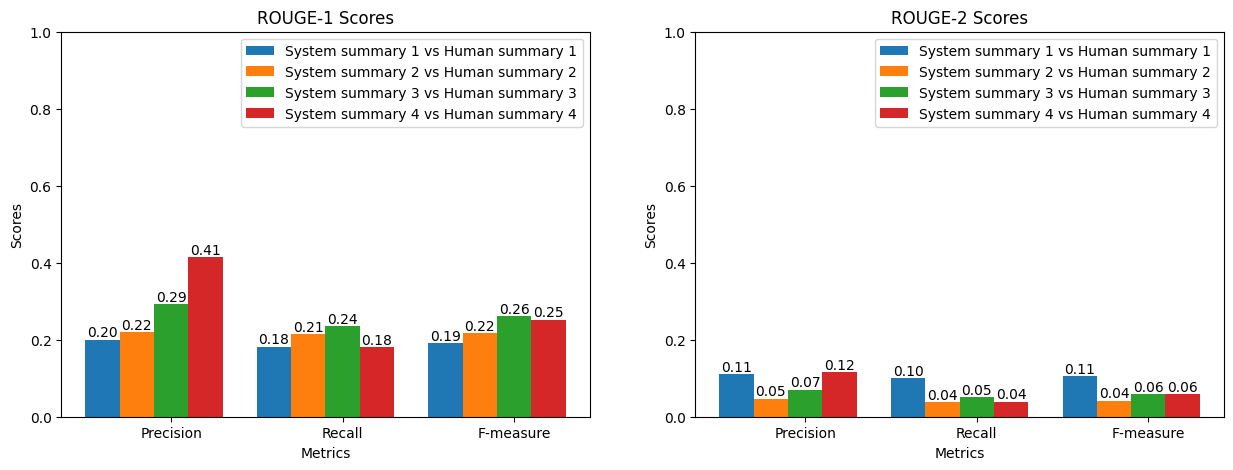

In [ ]:
'''
provide specific path where you want to store the stats calculated by rouge , for example :

/content/drive/MyDrive/Text Summarizer/Computer Generated Summaries/Corona Lockdown

here i am storing excel file for corona lockdown in same path

'''

def calculate_rouge(system_summary, human_summary):
    rouge = Rouge()
    scores = rouge.get_scores(system_summary, human_summary)
    return scores[0]

# List to store ROUGE scores
rouge_scores = []
for sys_sum, hum_sum in zip(comp_summary, human_summary_processed):
    rouge_scores.append(calculate_rouge(sys_sum, hum_sum))

# Print ROUGE scores for each summary
for idx, (sys_sum, hum_sum) in enumerate(zip(comp_summary, human_summary_processed)):
    print(f"ROUGE scores for system summary {idx+1} vs human summary {idx+1}:")
    scores = rouge_scores[idx]
    for metric, score in scores.items():
        print(f"{metric}: {score}")

# Extract ROUGE scores for plotting
metrics = ['Precision', 'Recall', 'F-measure']
scores_1 = [[score['rouge-1']['p'], score['rouge-1']['r'], score['rouge-1']['f']] for score in rouge_scores]
scores_2 = [[score['rouge-2']['p'], score['rouge-2']['r'], score['rouge-2']['f']] for score in rouge_scores]

# Save data in Excel sheet
columns = ['System', 'Human', 'Precision-1', 'Recall-1', 'F-measure-1', 'Precision-2', 'Recall-2', 'F-measure-2']
data = []

for idx, (sys_sum, hum_sum, score) in enumerate(zip(comp_summary, human_summary_processed, rouge_scores)):
    data.append([f"System {idx+1}", f"Human {idx+1}", score['rouge-1']['p'], score['rouge-1']['r'], score['rouge-1']['f'],
                 score['rouge-2']['p'], score['rouge-2']['r'], score['rouge-2']['f']])

df = pd.DataFrame(data, columns=columns)

# Save DataFrame to an Excel file
excel_file_path = '/content/drive/MyDrive/Text Summarizer/Computer Generated Summaries/Corona Lockdown/rouge_scores.xlsx'
df.to_excel(excel_file_path, index=False)

# Plotting ROUGE-1 Scores
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
for i in range(len(comp_summary)):
    bar_width = 0.2
    metrics_indices = range(len(metrics))
    bars = plt.bar([index + i * bar_width for index in metrics_indices], scores_1[i], bar_width, label=f"System summary {i+1} vs Human summary {i+1}")
    for bar, score in zip(bars, scores_1[i]):
        plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f'{score:.2f}', ha='center', va='bottom')
plt.title('ROUGE-1 Scores')
plt.xlabel('Metrics')
plt.ylabel('Scores')
plt.ylim(0, 1)  # Set y-axis limits
plt.xticks([index + 0.4 for index in metrics_indices], metrics)
plt.legend()

# Plotting ROUGE-2 Scores
plt.subplot(1, 2, 2)
for i in range(len(comp_summary)):
    bar_width = 0.2
    metrics_indices = range(len(metrics))
    bars = plt.bar([index + i * bar_width for index in metrics_indices], scores_2[i], bar_width, label=f"System summary {i+1} vs Human summary {i+1}")
    for bar, score in zip(bars, scores_2[i]):
        plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f'{score:.2f}', ha='center', va='bottom')
plt.title('ROUGE-2 Scores')
plt.xlabel('Metrics')
plt.ylabel('Scores')
plt.ylim(0, 1)  # Set y-axis limits
plt.xticks([index + 0.4 for index in metrics_indices], metrics)
plt.legend()

# Show the plot
plt.show()


# **Calculating Average Accuray of System**

Average ROUGE scores:
rouge-1:
p: 0.46
r: 0.46
f: 0.40


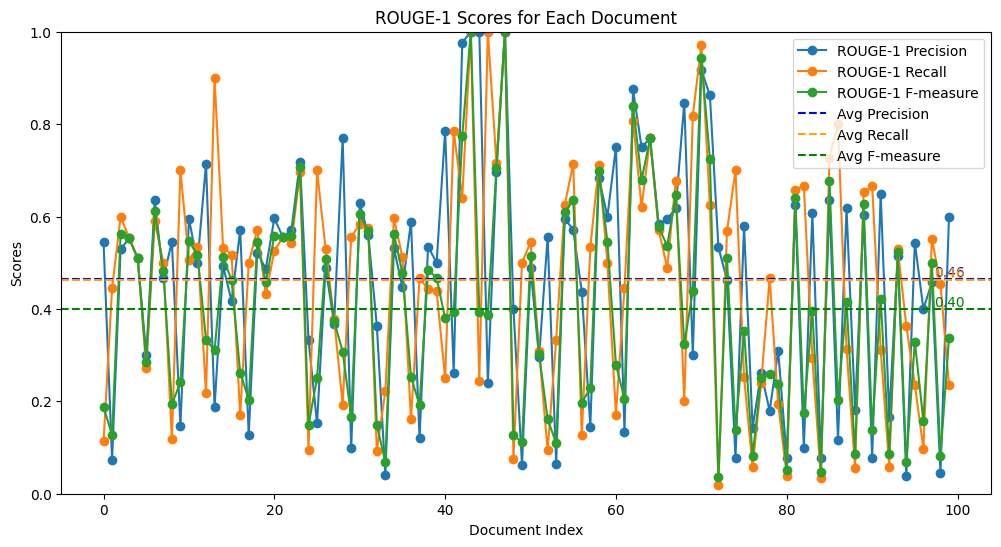

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from rouge import Rouge

def get_all_files(directory):
    """Recursively get all file paths in the given directory."""
    file_paths = []
    for root, _, files in os.walk(directory):
        for file in files:
            file_paths.append(os.path.join(root, file))
    return sorted(file_paths)  # Sorting to ensure corresponding files align correctly

def read_files(file_paths):
    """Read the content of each file in the file paths list."""
    contents = []
    for file_path in file_paths:
        with open(file_path, 'r', encoding='utf-8') as file:
            contents.append(file.read().strip())
    return contents

def calculate_rouge(system_summary, human_summary):
    rouge = Rouge()
    scores = rouge.get_scores(system_summary, human_summary)
    return scores[0]

# Define the base directories (modify these paths according to your directory structure)
system_summary_base_dir = '/content/drive/MyDrive/Text Summarizer/comp summary_'
human_summary_base_dir = '/content/drive/MyDrive/Text Summarizer/Urdu DataSet/x_Human Generated Summaries'

comp_summary = read_files(system_files)
human_summary_processed = read_files(human_files)

# List to store ROUGE scores
rouge_scores = []
for sys_sum, hum_sum in zip(comp_summary, human_summary_processed):
    rouge_scores.append(calculate_rouge(sys_sum, hum_sum))

# Prepare data for plotting
rouge_1_p = [score['rouge-1']['p'] for score in rouge_scores]
rouge_1_r = [score['rouge-1']['r'] for score in rouge_scores]
rouge_1_f = [score['rouge-1']['f'] for score in rouge_scores]

# Calculate average ROUGE scores
avg_rouge_scores = {
    'rouge-1': {
        'p': sum(rouge_1_p) / len(rouge_1_p),
        'r': sum(rouge_1_r) / len(rouge_1_r),
        'f': sum(rouge_1_f) / len(rouge_1_f),
    }
}

# Print average ROUGE scores
print("Average ROUGE scores:")
for metric, score in avg_rouge_scores.items():
    print(f"{metric}:")
    for sub_metric, value in score.items():
        print(f"{sub_metric}: {value:.2f}")

# Plotting ROUGE-1 Scores for each document
plt.figure(figsize=(12, 6))

metrics = ['Precision', 'Recall', 'F-measure']
for i, metric in enumerate(metrics):
    plt.plot(range(len(rouge_scores)), [score[f'rouge-1'][metric[0].lower()] for score in rouge_scores],
             marker='o', linestyle='-', label=f"ROUGE-1 {metric}")

# Plotting average scores as a horizontal line
plt.axhline(y=avg_rouge_scores['rouge-1']['p'], color='blue', linestyle='--', label="Avg Precision")
plt.axhline(y=avg_rouge_scores['rouge-1']['r'], color='orange', linestyle='--', label="Avg Recall")
plt.axhline(y=avg_rouge_scores['rouge-1']['f'], color='green', linestyle='--', label="Avg F-measure")

# Annotate average lines
plt.text(len(rouge_scores) - 1, avg_rouge_scores['rouge-1']['p'], f'{avg_rouge_scores["rouge-1"]["p"]:.2f}',
         ha='center', va='bottom', color='blue')
plt.text(len(rouge_scores) - 1, avg_rouge_scores['rouge-1']['r'], f'{avg_rouge_scores["rouge-1"]["r"]:.2f}',
         ha='center', va='bottom', color='orange')
plt.text(len(rouge_scores) - 1, avg_rouge_scores['rouge-1']['f'], f'{avg_rouge_scores["rouge-1"]["f"]:.2f}',
         ha='center', va='bottom', color='green')

plt.title('ROUGE-1 Scores for Each Document')
plt.xlabel('Document Index')
plt.ylabel('Scores')
plt.ylim(0, 1)  # Set y-axis limits
plt.legend()

# Show the plot
plt.show()


# **Line Chart**

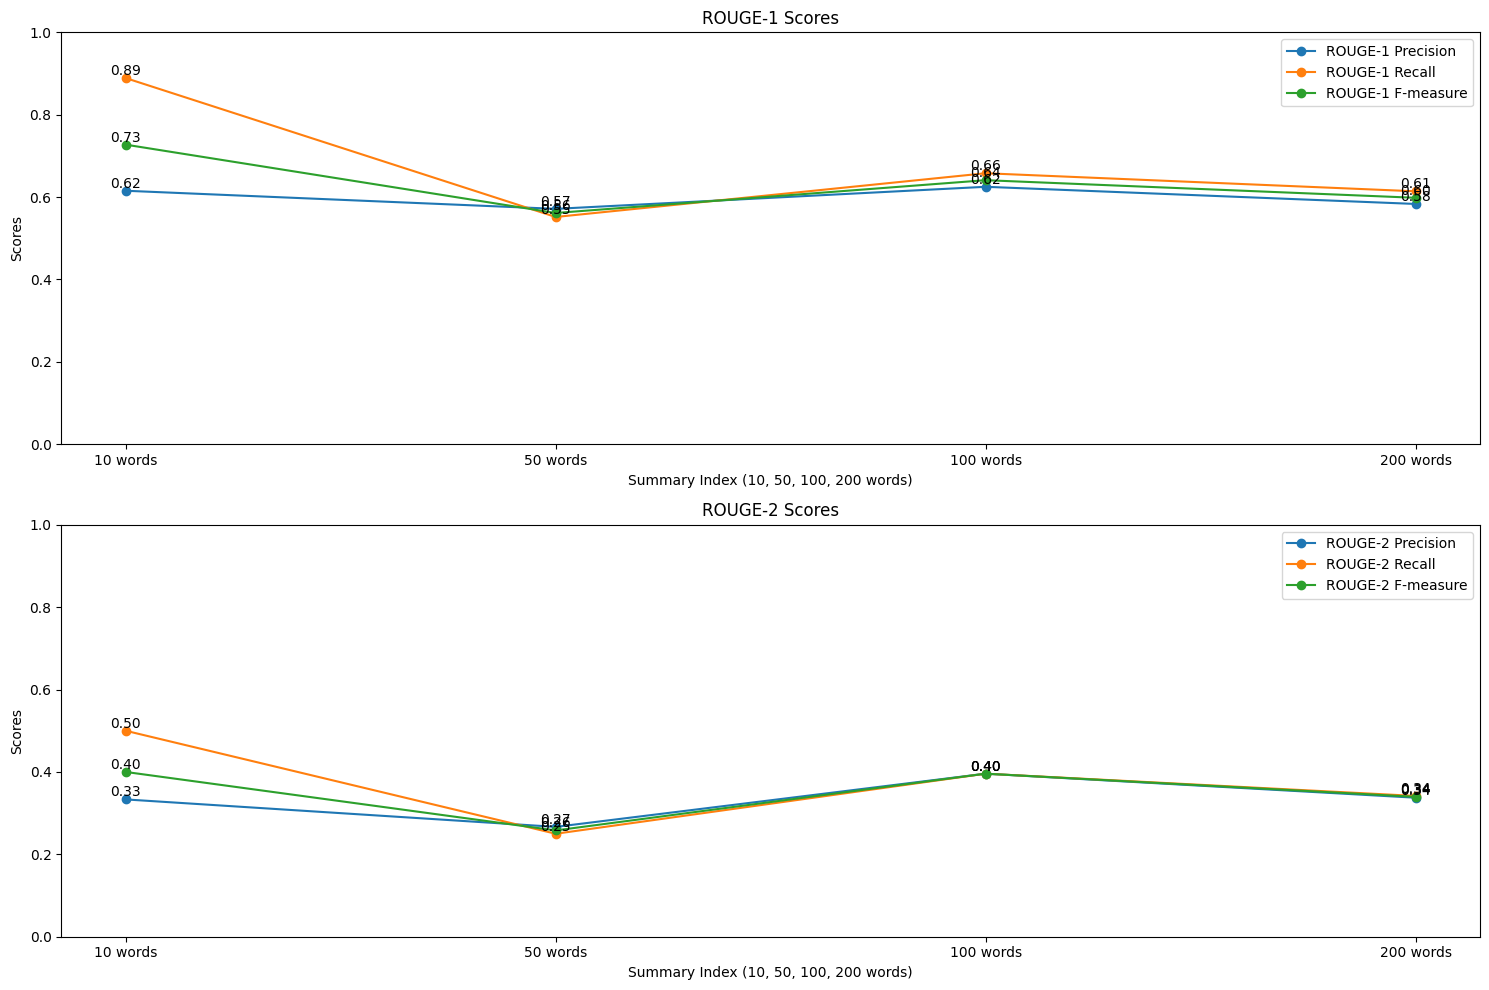

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from rouge import Rouge

def calculate_rouge(system_summary, human_summary):
    rouge = Rouge()
    scores = rouge.get_scores(system_summary, human_summary)
    return scores[0]

comp_summary_path = '/content/drive/MyDrive/Text Summarizer/comp summary _/sport_'
human_summary_path = '/content/drive/MyDrive/Text Summarizer/Urdu DataSet/x_Human Generated Summaries/sport'

comp_summary = read_files_from_path(comp_summary_path)
human_summary = read_files_from_path(human_summary_path)
human_summary_processed = clean_human_summmary(human_summary)

# List to store ROUGE scores
rouge_scores = []
for sys_sum, hum_sum in zip(comp_summary, human_summary_processed):
    rouge_scores.append(calculate_rouge(sys_sum, hum_sum))

# Extract ROUGE scores for plotting
metrics = ['Precision', 'Recall', 'F-measure']
scores_1 = [[score['rouge-1']['p'], score['rouge-1']['r'], score['rouge-1']['f']] for score in rouge_scores]
scores_2 = [[score['rouge-2']['p'], score['rouge-2']['r'], score['rouge-2']['f']] for score in rouge_scores]

# Save data in Excel sheet
columns = ['System', 'Human', 'Precision-1', 'Recall-1', 'F-measure-1', 'Precision-2', 'Recall-2', 'F-measure-2']
data = []

for idx, (sys_sum, hum_sum, score) in enumerate(zip(comp_summary, human_summary_processed, rouge_scores)):
    data.append([f"System {idx+1}", f"Human {idx+1}", score['rouge-1']['p'], score['rouge-1']['r'], score['rouge-1']['f'],
                 score['rouge-2']['p'], score['rouge-2']['r'], score['rouge-2']['f']])

df = pd.DataFrame(data, columns=columns)

# # Save DataFrame to an Excel file
# excel_file_path = '/content/drive/MyDrive/Text Summarizer/Computer Generated Summaries/Corona Lockdown/rouge_scores.xlsx'
# df.to_excel(excel_file_path, index=False)

# Plotting ROUGE-1 and ROUGE-2 Scores as Line Charts
plt.figure(figsize=(15, 10))

# Plot ROUGE-1 Scores
plt.subplot(2, 1, 1)
for metric_idx, metric in enumerate(metrics):
    metric_scores = [scores_1[i][metric_idx] for i in range(len(scores_1))]
    plt.plot(range(len(metric_scores)), metric_scores, marker='o', label=f'ROUGE-1 {metric}')
    for idx, score in enumerate(metric_scores):
        plt.text(idx, score, f'{score:.2f}', ha='center', va='bottom')
plt.title('ROUGE-1 Scores')
plt.xlabel('Summary Index (10, 50, 100, 200 words)')
plt.ylabel('Scores')
plt.ylim(0, 1)  # Set y-axis limits
plt.xticks(range(len(comp_summary)), ['10 words', '50 words', '100 words', '200 words'])
plt.legend()

# Plot ROUGE-2 Scores
plt.subplot(2, 1, 2)
for metric_idx, metric in enumerate(metrics):
    metric_scores = [scores_2[i][metric_idx] for i in range(len(scores_2))]
    plt.plot(range(len(metric_scores)), metric_scores, marker='o', label=f'ROUGE-2 {metric}')
    for idx, score in enumerate(metric_scores):
        plt.text(idx, score, f'{score:.2f}', ha='center', va='bottom')
plt.title('ROUGE-2 Scores')
plt.xlabel('Summary Index (10, 50, 100, 200 words)')
plt.ylabel('Scores')
plt.ylim(0, 1)  # Set y-axis limits
plt.xticks(range(len(comp_summary)), ['10 words', '50 words', '100 words', '200 words'])
plt.legend()

# Show the plot
plt.tight_layout()
plt.show()


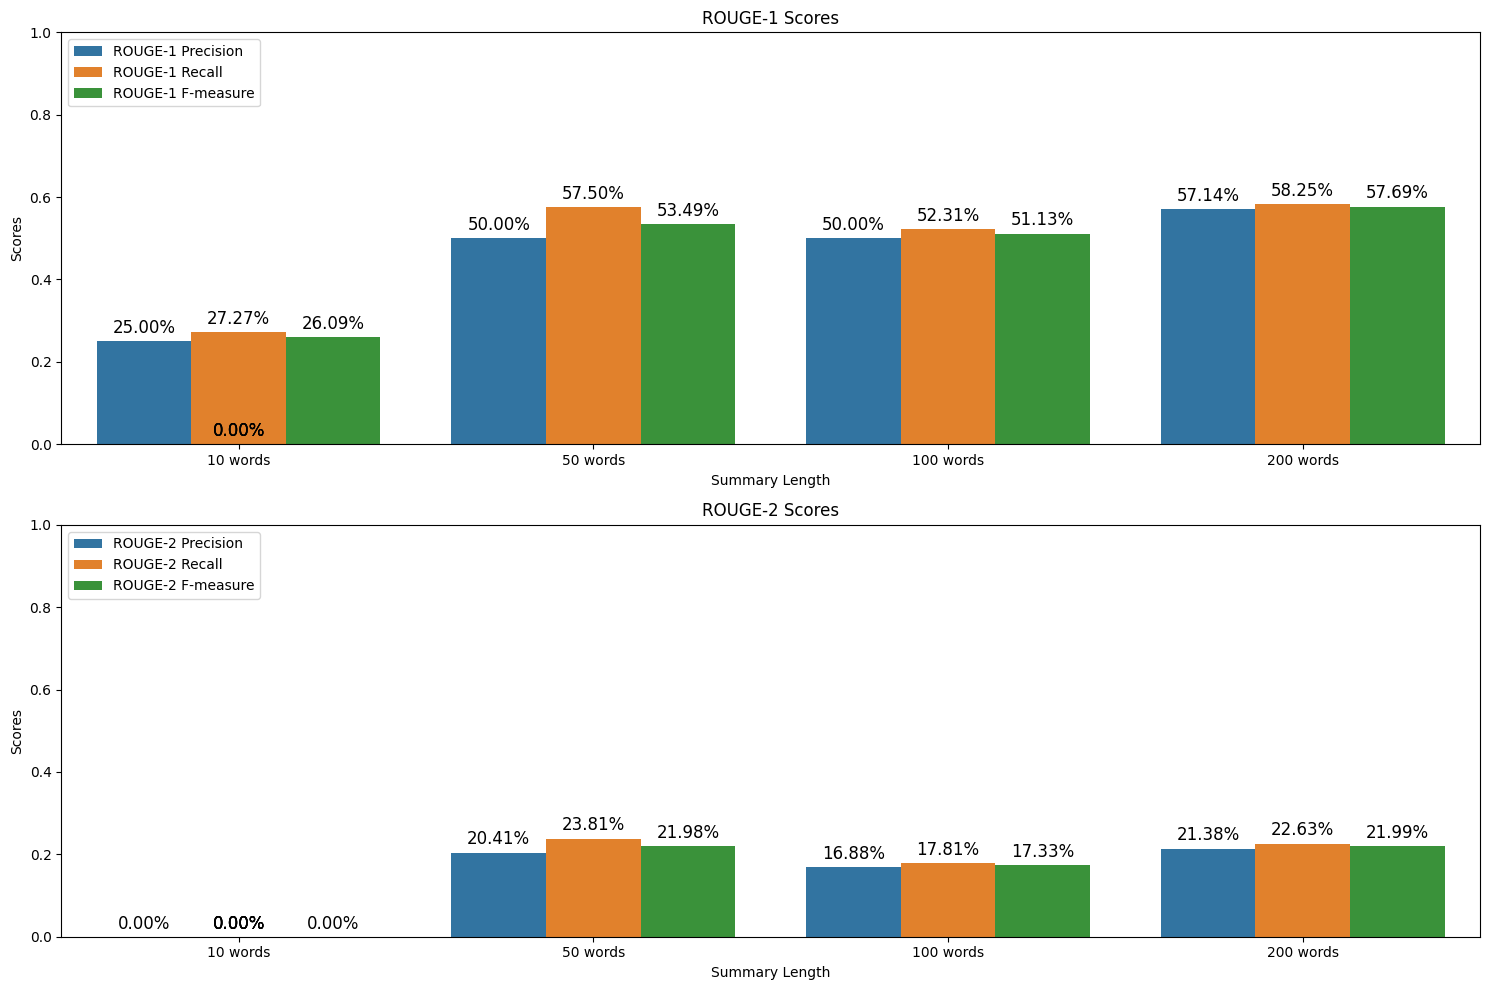

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from rouge import Rouge

def calculate_rouge(system_summary, human_summary):
    rouge = Rouge()
    scores = rouge.get_scores(system_summary, human_summary)
    return scores[0]

comp_summary_path = '/content/drive/MyDrive/Text Summarizer/comp summary _/worldnews3_'
human_summary_path = '/content/drive/MyDrive/Text Summarizer/Urdu DataSet/x_Human Generated Summaries/worldnews3'

comp_summary = read_files_from_path(comp_summary_path)
human_summary = read_files_from_path(human_summary_path)
human_summary_processed = clean_human_summmary(human_summary)

# List to store ROUGE scores
rouge_scores = []
for sys_sum, hum_sum in zip(comp_summary, human_summary_processed):
    rouge_scores.append(calculate_rouge(sys_sum, hum_sum))

# Extract ROUGE scores for plotting
metrics = ['Precision', 'Recall', 'F-measure']
scores_1 = [[score['rouge-1']['p'], score['rouge-1']['r'], score['rouge-1']['f']] for score in rouge_scores]
scores_2 = [[score['rouge-2']['p'], score['rouge-2']['r'], score['rouge-2']['f']] for score in rouge_scores]

# Prepare data for plotting
summary_indices = ['10 words', '50 words', '100 words', '200 words']
data_1 = {'Summary Index': [], 'Metric': [], 'Score': []}
data_2 = {'Summary Index': [], 'Metric': [], 'Score': []}

for idx, summary_index in enumerate(summary_indices):
    for metric_idx, metric in enumerate(metrics):
        data_1['Summary Index'].append(summary_index)
        data_1['Metric'].append(f'ROUGE-1 {metric}')
        data_1['Score'].append(scores_1[idx][metric_idx])

        data_2['Summary Index'].append(summary_index)
        data_2['Metric'].append(f'ROUGE-2 {metric}')
        data_2['Score'].append(scores_2[idx][metric_idx])

df_1 = pd.DataFrame(data_1)
df_2 = pd.DataFrame(data_2)

# Plotting ROUGE-1 and ROUGE-2 Scores as Grouped Bar Plots with Accuracy Percentage
plt.figure(figsize=(15, 10))

# Plot ROUGE-1 Scores
plt.subplot(2, 1, 1)
barplot_1 = sns.barplot(data=df_1, x='Summary Index', y='Score', hue='Metric')
for p in barplot_1.patches:
    height = p.get_height()
    barplot_1.annotate(f'{height*100:.2f}%', (p.get_x() + p.get_width() / 2., height),
                       ha='center', va='bottom', fontsize=12, color='black', xytext=(0, 3),
                       textcoords='offset points')
plt.title('ROUGE-1 Scores')
plt.xlabel('Summary Length')
plt.ylabel('Scores')
plt.ylim(0, 1)  # Set y-axis limits
plt.legend(loc='upper left')

# Plot ROUGE-2 Scores
plt.subplot(2, 1, 2)
barplot_2 = sns.barplot(data=df_2, x='Summary Index', y='Score', hue='Metric')
for p in barplot_2.patches:
    height = p.get_height()
    barplot_2.annotate(f'{height*100:.2f}%', (p.get_x() + p.get_width() / 2., height),
                       ha='center', va='bottom', fontsize=12, color='black', xytext=(0, 3),
                       textcoords='offset points')
plt.title('ROUGE-2 Scores')
plt.xlabel('Summary Length')
plt.ylabel('Scores')
plt.ylim(0, 1)  # Set y-axis limits
plt.legend(loc='upper left')

# Show the plot
plt.tight_layout()
plt.show()
